CMSC320 - Project Checkpoint 2


By: Caroline, Sangeetha, Luis, Ethan


Data preprocessing stage: In addition to importing the csv file, we are improving the readability of the dataframe by shortening the sector names via

the exclusion of 'carbon dioxide emissions', as that is the sole focus of the dataset (thus it becomes redundant to keep

listing it).

In [5]:
import pandas as pd

df = pd.read_csv('emissions.csv')

df['year'] = df['year'].astype(int)
df['value'] = df['value'].astype(float)
df['sector-name'] = df['sector-name'].str.replace(' carbon dioxide emissions', '', regex=False)


df.head(10)


,year,state-name,sector-name,fuel-name,value
0,1970,Alabama,Industrial,Coal,26.721507
1,1970,Alabama,Industrial,Petroleum,3.577779
2,1970,Alabama,Industrial,Natural Gas,8.944097
3,1970,Alabama,Industrial,All Fuels,39.243383
4,1970,Alabama,Total from all sectors,All Fuels,102.646851
5,1970,Alabama,Total from all sectors,Coal,63.266935
6,1970,Alabama,Total from all sectors,Petroleum,23.474612
7,1970,Alabama,Total from all sectors,Natural Gas,15.905305
8,1970,Alabama,Residential,Coal,0.163635
9,1970,Alabama,Residential,Petroleum,1.123947


Data Exploration: Kruskal-Wallis test

Motivation for Selection: We must first consider the fact that this is a dataset made up of states varying in population
size. Naturally, this influences the C02 emissions value, and the likelihood of outliers. For example, California's
total CO2 for all fuels is roughly 304.47 million metric tons while Alaska's is 12.78 in the year 1974. ANOVA compares group means, but reacts
poorly to the presence of outliers, so we will need a test that can handle this issue. The lack of a normal distributed
dataset and categorical variables (e.g., fuel name) makes the selection of a non-parametric test appealing. Kruskal-Wallis
achieves our goal of comparing categorical variables by using group medians, which is an appropriate choice considering
our circumstances. First, we can create separate dataframes for each sector (in the year 2021) from the dictionary, which make up a total
of 616 samples and gives a narrower analysis of the original dataset. We want to be carefully of the rows that contain
aggregated values (i.e, total from all sectors) to ensure the validity of our results.

In [6]:

import matplotlib.pyplot as plt
from scipy import stats

modified_df = df[(df['sector-name'] != 'Total from all sectors') & (df['fuel-name'] != 'All Fuels') &(df['year'] == 2021)]

print('Samples:',modified_df.shape[0])


sector_dict = {sector_type: group for sector_type, group in modified_df.drop_duplicates().groupby('sector-name')}


resid= sector_dict['Residential']
comm= sector_dict['Commercial']
transport= sector_dict['Transportation']
elec = sector_dict['Electric Power']
industrial = sector_dict['Industrial']

display('Residential Data:', resid.head())
display('Commercial Data: ', comm.head())
display('Transportation Data: ',transport.head())
display('Electrical Data: ',elec.head())
display('Industrial Data: ',industrial.head())

Samples: 616


'Residential Data:'

,year,state-name,sector-name,fuel-name,value
58823,2021,Alabama,Residential,Natural Gas,1.755607
58842,2021,Alabama,Residential,Petroleum,0.295148
58844,2021,Alaska,Residential,Natural Gas,1.113967
58864,2021,Alaska,Residential,Petroleum,0.616132
58873,2021,Arizona,Residential,Petroleum,0.321582


'Commercial Data: '

,year,state-name,sector-name,fuel-name,value
58825,2021,Alabama,Commercial,Petroleum,0.931477
58826,2021,Alabama,Commercial,Natural Gas,1.400739
58846,2021,Alaska,Commercial,Coal,0.706643
58847,2021,Alaska,Commercial,Petroleum,0.727085
58848,2021,Alaska,Commercial,Natural Gas,0.869787


...

,year,state-name,sector-name,fuel-name,value
58828,2021,Alabama,Transportation,Petroleum,35.796333
58829,2021,Alabama,Transportation,Natural Gas,1.368041
58850,2021,Alaska,Transportation,Petroleum,13.624604
58851,2021,Alaska,Transportation,Natural Gas,0.025608
58879,2021,Arizona,Transportation,Petroleum,37.429561


'Electrical Data: '

,year,state-name,sector-name,fuel-name,value
58831,2021,Alabama,Electric Power,Coal,25.898401
58832,2021,Alabama,Electric Power,Petroleum,0.015644
58833,2021,Alabama,Electric Power,Natural Gas,21.290137
58853,2021,Alaska,Electric Power,Coal,1.083132
58854,2021,Alaska,Electric Power,Petroleum,0.364695


'Industrial Data: '

,year,state-name,sector-name,fuel-name,value
58835,2021,Alabama,Industrial,Coal,3.698439
58836,2021,Alabama,Industrial,Petroleum,3.194382
58837,2021,Alabama,Industrial,Natural Gas,12.747755
58857,2021,Alaska,Industrial,Coal,0.002105
58858,2021,Alaska,Industrial,Petroleum,2.124507


Hypothesis Testing & Plotting Data: Now, we must create our null and alternative hypotheses. This is based
on whether the medians of the sectors will be the same or different, specifically if CO2 values will differentiate depending on the
sector. Next, the data is presented in the form of a boxplot with the y-axis scaled by log to account for the fact that
outliers can cause the plot to appear compressed. The ranks of each sector are analyzed below.

HO: The type of sector has no effect on the carbon dioxide emissions value.

HA:The type of sector has an effect on the carbon dioxide emissions value.

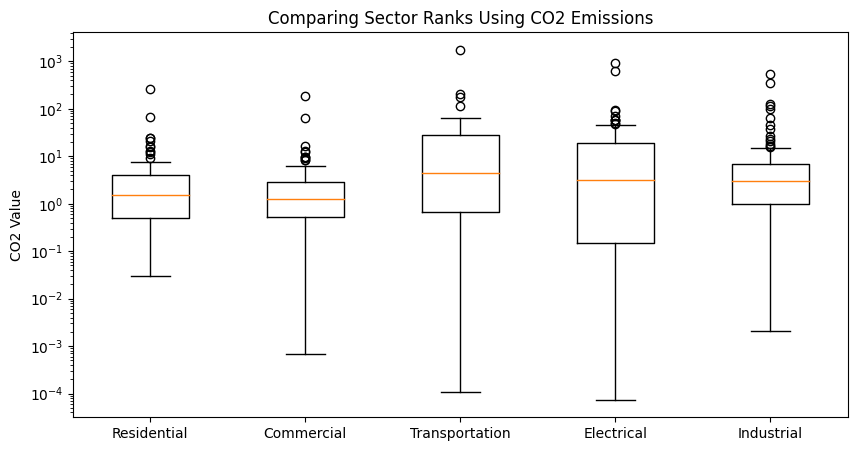

In [7]:
stat, p_value = stats.kruskal(resid['value'],comm['value'],transport['value'],elec['value'], industrial['value'])
plt.figure(figsize=(10,5))
plt.boxplot([resid['value'],comm['value'],transport['value'],elec['value'], industrial['value']], labels=['Residential','Commercial', 'Transportation','Electrical','Industrial'])
plt.yscale('log') #to increase readibility as many values lie close to 0 
plt.title(f'Comparing Sector Ranks Using CO2 Emissions')
plt.ylabel(f'CO2 Value')
plt.show()


P-value analysis:

Assume the alpha value is 0.05.

We see that our p-value is signficantly smaller than our alpha value, so we are able to reject

the null hypothesis and discern that at least one group's median differs from the others. Most importantly,
the long distance from alpha highlights that the statistical significance has little ambiguity.

In [9]:
print(f'The p-value is {p_value}')

The p-value is 7.901061439275599e-06


Conclusion & Plot-Analysis:
We notice that the transportation's and electrical's box lengths stand out amongst the others. The longer sizing tells us
that there is greater variability in CO2 values for transportation and electrical, meaning that there is a bigger buffer
space for outliers. In contrast, the other sectors showcase higher consistency and thus, are more sensitive/quick to label
data points as outliers. Additionally, we notice that transportation, electrical, and industrial have outliers placed near
the very top of the plot. These findings can be informative for policymakers, as the scale and factors contributing
to the variability of electrical and transportation ranks need more researching, since there isn't a level of uniformity
that implies that there are dominant factors.

Chi Square Test of Independence

emission_level  High Emitter  Low Emitter
sector-name                              
Commercial                38           81
Electric Power            77           67
Industrial                91           54
Residential               42           62
Transportation            60           44

Chi-square statistic: 31.98
Degrees of freedom: 4
p-value: 1.9300e-06


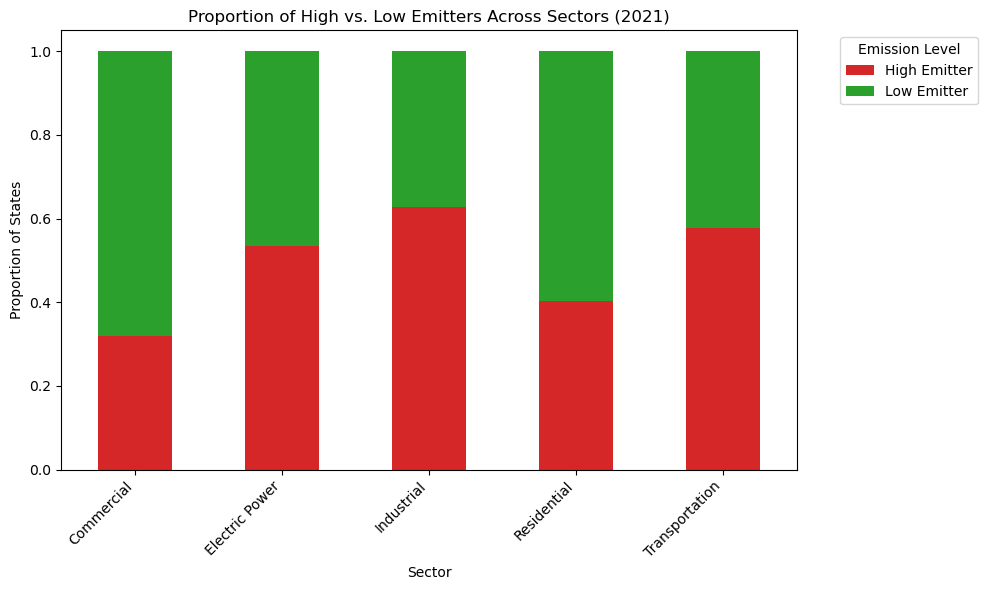

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv('emissions.csv')
df['year'] = df['year'].astype(int)
df['value'] = df['value'].astype(float) #CO2 values are floats
df['sector-name'] = df['sector-name'].str.replace(' carbon dioxide emissions', '', regex=False)

clean_df = df[(df['sector-name'] != 'Total from all sectors') & (df['fuel-name'] != 'All Fuels') & (df['year'] == 2021)].copy()
#above code makes sure it keeps only year 2021 so it filters out Total from all sectors and All Fuels 

median = clean_df['value'].median() #chi-square needs categorical data 
clean_df['emission_level'] = np.where(clean_df['value'] > median, 'High Emitter', 'Low Emitter')
#if a row's CO2 value is greater than the median, it labels it 'High Emitter' else 'Low Emitter'

table = pd.crosstab(clean_df['sector-name'], clean_df['emission_level'])
print(table)

test_statistic, p, dof, expected = stats.chi2_contingency(table) 
print(f"\nChi-square statistic: {test_statistic:.2f}")
print(f"Degrees of freedom: {dof}")
print(f"p-value: {p:.4e}")
divide_counts_by_row_total = table.div(contingency.sum(axis=1), axis=0)

divide_counts_by_row_total.plot(kind='bar', stacked=True, figsize=(10, 6), color=['#d62728', '#2ca02c'])
plt.title('Proportion of High vs. Low Emitters Across Sectors (2021)')
plt.xlabel('Sector')
plt.ylabel('Proportion of States')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Emission Level', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Hypothesis Testing and Conclusion:

Null Hypothesis: The proportion of High vs. Low emitters is independent of the sector.
Alternative Hypothesis: The proportion of High vs. Low emitters depends on the sector.

We used the Chi-Square Test of Independence on the 2021 data, using the median CO2 value to categorize emissions into 
"High" and "Low". We got a test statistic of 31.98 with 4 degrees of freedom and a p-value of 1.93e-06. 

Since the p-value is significantly lower than the alpha of 0.05, we reject the null hypothesis. There is a statistically significant 
association between the sector and the likelihood of a state having high CO2 emissions. 

As you can see in the stacked bar chart, sectors like Industrial (91 high vs 54 low) and Electric Power (77 high vs 67 low) 
are skewed heavily towards being high emitters. Commercial and Residential are predominantly low emitters. 
This shows that Industrial and Electric Power are the primary contributors to extreme CO2 emissions.  